In [1]:
!pip install -q kaggle

In [2]:
from google.colab import files

uploaded = files.upload()

Saving kaggle (5).json to kaggle (5).json


In [3]:
import os
import shutil

uploaded_file = list(uploaded.keys())[0]

os.makedirs('/root/.kaggle', exist_ok=True)

shutil.copy(
    uploaded_file,
    '/root/.kaggle/kaggle.json'
)

os.chmod(
    '/root/.kaggle/kaggle.json',
    0o600
)

print("Kaggle API configured successfully!")

Kaggle API configured successfully!


In [4]:
!kaggle --version

Kaggle CLI 2.0.2


In [5]:
!mkdir -p /content/traffic_data

!kaggle datasets download \
-d hasibullahaman/traffic-prediction-dataset \
-p /content/traffic_data \
--unzip

Dataset URL: https://www.kaggle.com/datasets/hasibullahaman/traffic-prediction-dataset
License(s): other
100% 83.1k/83.1k [00:00<00:00, 77.4MB/s]



In [6]:
import os

print("Downloaded files:")

for file in os.listdir('/content/traffic_data'):
    print(file)

Downloaded files:
TrafficTwoMonth.csv
Traffic.csv


In [7]:
import pandas as pd
import numpy as np

df = pd.read_csv(
    '/content/traffic_data/TrafficTwoMonth.csv'
)

print("Dataset loaded successfully!")

print("Dataset Shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Dataset Shape: (5952, 9)


,Time,Date,Day of the week,CarCount,BikeCount,BusCount,TruckCount,Total,Traffic Situation
0,12:00:00 AM,10,Tuesday,13,2,2,24,41,normal
1,12:15:00 AM,10,Tuesday,14,1,1,36,52,normal
2,12:30:00 AM,10,Tuesday,10,2,2,32,46,normal
3,12:45:00 AM,10,Tuesday,10,2,2,36,50,normal
4,1:00:00 AM,10,Tuesday,11,2,1,34,48,normal


In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5952 entries, 0 to 5951
Data columns (total 9 columns):
 #   Column             Non-Null Count  Dtype 
---  ------             --------------  ----- 
 0   Time               5952 non-null   object
 1   Date               5952 non-null   int64 
 2   Day of the week    5952 non-null   object
 3   CarCount           5952 non-null   int64 
 4   BikeCount          5952 non-null   int64 
 5   BusCount           5952 non-null   int64 
 6   TruckCount         5952 non-null   int64 
 7   Total              5952 non-null   int64 
 8   Traffic Situation  5952 non-null   object
dtypes: int64(6), object(3)
memory usage: 418.6+ KB


In [10]:
print("Traffic Situation Distribution:")

print(df['Traffic Situation'].value_counts())

Traffic Situation Distribution:
Traffic Situation
normal    3610
heavy     1137
low        834
high       371
Name: count, dtype: int64


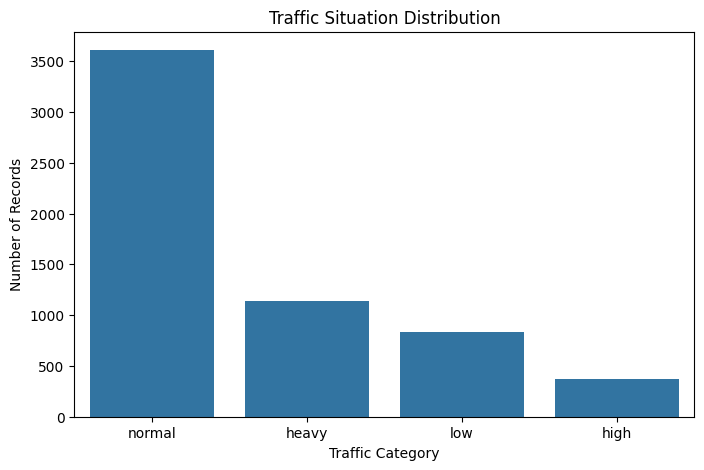

In [11]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8,5))

sns.countplot(
    data=df,
    x='Traffic Situation',
    order=df['Traffic Situation'].value_counts().index
)

plt.title("Traffic Situation Distribution")
plt.xlabel("Traffic Category")
plt.ylabel("Number of Records")

plt.show()

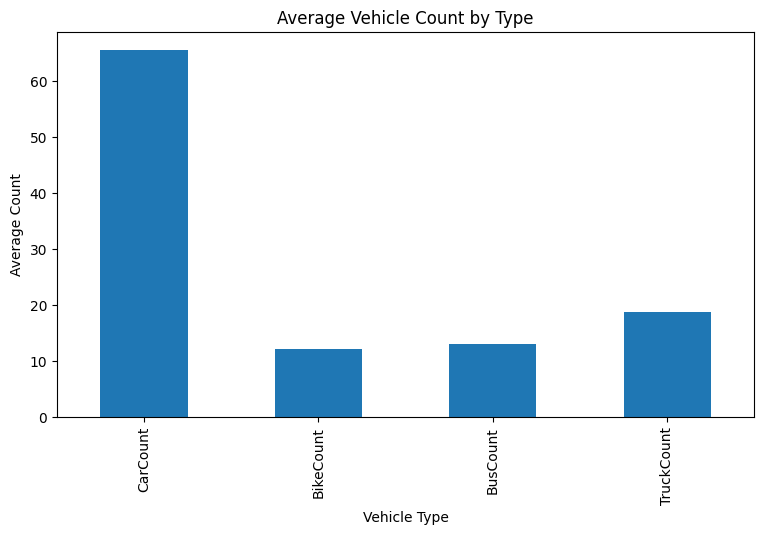

In [12]:
vehicle_columns = [
    'CarCount',
    'BikeCount',
    'BusCount',
    'TruckCount'
]

plt.figure(figsize=(9,5))

df[vehicle_columns].mean().plot(kind='bar')

plt.title("Average Vehicle Count by Type")
plt.xlabel("Vehicle Type")
plt.ylabel("Average Count")

plt.show()

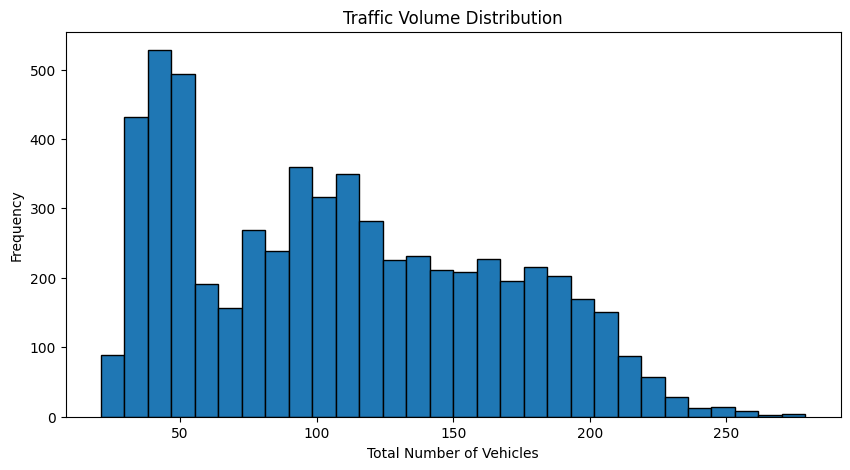

In [13]:
plt.figure(figsize=(10,5))

plt.hist(
    df['Total'],
    bins=30,
    edgecolor='black'
)

plt.title("Traffic Volume Distribution")
plt.xlabel("Total Number of Vehicles")
plt.ylabel("Frequency")

plt.show()

Data Preprocessing

In [14]:
import numpy as np
import pandas as pd

# Extract hour and minute
time_data = pd.to_datetime(
    df['Time'],
    format='%I:%M:%S %p'
)

df['Hour'] = time_data.dt.hour
df['Minute'] = time_data.dt.minute

# Convert time into cyclic features
minutes = df['Hour'] * 60 + df['Minute']

df['Time_Sin'] = np.sin(
    2 * np.pi * minutes / 1440
)

df['Time_Cos'] = np.cos(
    2 * np.pi * minutes / 1440
)

print("Time features created successfully!")

display(df[['Time', 'Hour', 'Minute',
            'Time_Sin', 'Time_Cos']].head())

Time features created successfully!


,Time,Hour,Minute,Time_Sin,Time_Cos
0,12:00:00 AM,0,0,0.000000,1.000000
1,12:15:00 AM,0,15,0.065403,0.997859
2,12:30:00 AM,0,30,0.130526,0.991445
3,12:45:00 AM,0,45,0.195090,0.980785
4,1:00:00 AM,1,0,0.258819,0.965926


In [15]:
day_mapping = {
    'Monday': 0,
    'Tuesday': 1,
    'Wednesday': 2,
    'Thursday': 3,
    'Friday': 4,
    'Saturday': 5,
    'Sunday': 6
}

df['Day_Number'] = df['Day of the week'].map(day_mapping)

df['Day_Sin'] = np.sin(
    2 * np.pi * df['Day_Number'] / 7
)

df['Day_Cos'] = np.cos(
    2 * np.pi * df['Day_Number'] / 7
)

print("Day encoding completed!")

display(df[['Day of the week',
            'Day_Number',
            'Day_Sin',
            'Day_Cos']].head())

Day encoding completed!


,Day of the week,Day_Number,Day_Sin,Day_Cos
0,Tuesday,1,0.781831,0.62349
1,Tuesday,1,0.781831,0.62349
2,Tuesday,1,0.781831,0.62349
3,Tuesday,1,0.781831,0.62349
4,Tuesday,1,0.781831,0.62349


In [16]:
vehicle_columns = [
    'CarCount',
    'BikeCount',
    'BusCount',
    'TruckCount',
    'Total'
]

# Previous 15 minutes
for col in vehicle_columns:
    df[f'{col}_lag1'] = df[col].shift(1)

# Previous 1 hour
for col in vehicle_columns:
    df[f'{col}_lag4'] = df[col].shift(4)

# Previous 24 hours
for col in vehicle_columns:
    df[f'{col}_lag96'] = df[col].shift(96)

print("Historical traffic features created!")

print("Dataset shape:", df.shape)

display(df.head())

Historical traffic features created!
Dataset shape: (5952, 31)


,Time,Date,Day of the week,CarCount,BikeCount,BusCount,TruckCount,Total,Traffic Situation,Hour,...,CarCount_lag4,BikeCount_lag4,BusCount_lag4,TruckCount_lag4,Total_lag4,CarCount_lag96,BikeCount_lag96,BusCount_lag96,TruckCount_lag96,Total_lag96
0,12:00:00 AM,10,Tuesday,13,2,2,24,41,normal,0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,12:15:00 AM,10,Tuesday,14,1,1,36,52,normal,0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,12:30:00 AM,10,Tuesday,10,2,2,32,46,normal,0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,12:45:00 AM,10,Tuesday,10,2,2,36,50,normal,0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,1:00:00 AM,10,Tuesday,11,2,1,34,48,normal,1,...,13.0,2.0,2.0,24.0,41.0,NaN,NaN,NaN,NaN,NaN


In [17]:
df = df.dropna().reset_index(drop=True)

print("Preprocessing completed!")

print("Final dataset shape:", df.shape)

print("Missing values:",
      df.isnull().sum().sum())

Preprocessing completed!
Final dataset shape: (5856, 31)
Missing values: 0


In [18]:
lag_columns = [
    col for col in df.columns
    if '_lag' in col
]

time_columns = [
    'Hour',
    'Minute',
    'Time_Sin',
    'Time_Cos',
    'Day_Sin',
    'Day_Cos'
]

feature_columns = lag_columns + time_columns

X = df[feature_columns].values.astype('float32')

y = df['Total'].values.astype('float32')

print("Input shape:", X.shape)
print("Target shape:", y.shape)

Input shape: (5856, 21)
Target shape: (5856,)


In [19]:
split_index = int(len(df) * 0.80)

X_train = X[:split_index]
X_test = X[split_index:]

y_train = y[:split_index]
y_test = y[split_index:]

print("Training input:", X_train.shape)
print("Testing input:", X_test.shape)

print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Training input: (4684, 21)
Testing input: (1172, 21)
Training target: (4684,)
Testing target: (1172,)


In [20]:
from sklearn.preprocessing import MinMaxScaler

scaler_X = MinMaxScaler()
scaler_y = MinMaxScaler()

X_train_scaled = scaler_X.fit_transform(X_train)

X_test_scaled = scaler_X.transform(X_test)

y_train_scaled = scaler_y.fit_transform(
    y_train.reshape(-1, 1)
)

y_test_scaled = scaler_y.transform(
    y_test.reshape(-1, 1)
)

print("Normalization completed!")

print("ANN training shape:", X_train_scaled.shape)
print("ANN testing shape:", X_test_scaled.shape)

Normalization completed!
ANN training shape: (4684, 21)
ANN testing shape: (1172, 21)


ANN Model Implementation

In [21]:
import tensorflow as tf

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

print("TensorFlow Version:", tf.__version__)

print("GPU Available:",
      tf.config.list_physical_devices('GPU'))

TensorFlow Version: 2.21.0
GPU Available: []


In [22]:
ann_model = Sequential([

    Dense(
        128,
        activation='relu',
        input_shape=(X_train_scaled.shape[1],)
    ),

    Dropout(0.2),

    Dense(64, activation='relu'),

    Dropout(0.2),

    Dense(32, activation='relu'),

    Dense(1)
])

ann_model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │         2,816 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 13,185 (51.50 KB)

 Trainable params: 13,185 (51.50 KB)

 Non-trainable params: 0 (0.00 B)

In [23]:
ann_model.compile(

    optimizer='adam',

    loss='mse',

    metrics=['mae']

)

print("ANN model compiled successfully!")

ANN model compiled successfully!


Training the ANN Model

In [24]:
early_stop = EarlyStopping(

    monitor='val_loss',

    patience=5,

    restore_best_weights=True

)

ann_history = ann_model.fit(

    X_train_scaled,

    y_train_scaled,

    epochs=10,

    batch_size=64,

    validation_split=0.2,

    callbacks=[early_stop],

    verbose=1

)

Epoch 1/10
59/59 ━━━━━━━━━━━━━━━━━━━━ 2s 12ms/step - loss: 0.0249 - mae: 0.1199 - val_loss: 0.0161 - val_mae: 0.0966
Epoch 2/10
59/59 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.0144 - mae: 0.0914 - val_loss: 0.0150 - val_mae: 0.0927
Epoch 3/10
59/59 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0129 - mae: 0.0857 - val_loss: 0.0148 - val_mae: 0.0922
Epoch 4/10
59/59 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0121 - mae: 0.0821 - val_loss: 0.0163 - val_mae: 0.0961
Epoch 5/10
59/59 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0110 - mae: 0.0785 - val_loss: 0.0180 - val_mae: 0.1013
Epoch 6/10
59/59 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0107 - mae: 0.0766 - val_loss: 0.0183 - val_mae: 0.1024
Epoch 7/10
59/59 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0101 - mae: 0.0745 - val_loss: 0.0163 - val_mae: 0.0964
Epoch 8/10
59/59 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0100 - mae: 0.0740 - val_loss: 0.0151 - val_mae: 0.0921


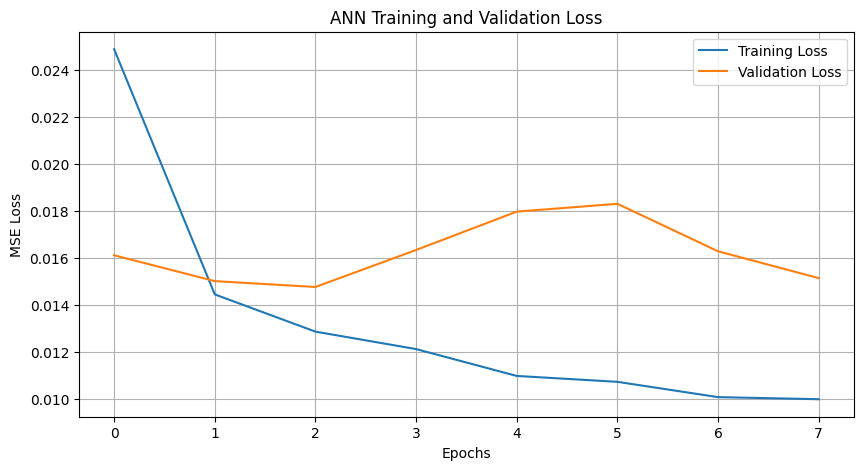

In [25]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10,5))

plt.plot(
    ann_history.history['loss'],
    label='Training Loss'
)

plt.plot(
    ann_history.history['val_loss'],
    label='Validation Loss'
)

plt.title("ANN Training and Validation Loss")

plt.xlabel("Epochs")

plt.ylabel("MSE Loss")

plt.legend()

plt.grid(True)

plt.show()

In [26]:
ann_predictions_scaled = ann_model.predict(
    X_test_scaled
)

ann_predictions = scaler_y.inverse_transform(
    ann_predictions_scaled
).flatten()

actual_values = y_test

print("ANN Predictions Generated!")

print("First 10 Predictions:")

for i in range(10):

    print(
        "Actual:", actual_values[i],
        "| Predicted:", round(ann_predictions[i], 2)
    )

37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step
ANN Predictions Generated!
First 10 Predictions:
Actual: 155.0 | Predicted: 109.93
Actual: 146.0 | Predicted: 110.26
Actual: 161.0 | Predicted: 108.03
Actual: 124.0 | Predicted: 109.72
Actual: 128.0 | Predicted: 101.09
Actual: 136.0 | Predicted: 99.41
Actual: 129.0 | Predicted: 105.7
Actual: 152.0 | Predicted: 99.43
Actual: 150.0 | Predicted: 127.13
Actual: 132.0 | Predicted: 114.59


In [27]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

mae = mean_absolute_error(
    actual_values,
    ann_predictions
)

mse = mean_squared_error(
    actual_values,
    ann_predictions
)

rmse = np.sqrt(mse)

r2 = r2_score(
    actual_values,
    ann_predictions
)

print("ANN MODEL PERFORMANCE")

print("----------------------")

print("MAE:", round(mae, 4))

print("MSE:", round(mse, 4))

print("RMSE:", round(rmse, 4))

print("R2 Score:", round(r2, 4))

ANN MODEL PERFORMANCE
----------------------
MAE: 22.7965
MSE: 913.6783
RMSE: 30.2271
R2 Score: 0.7433


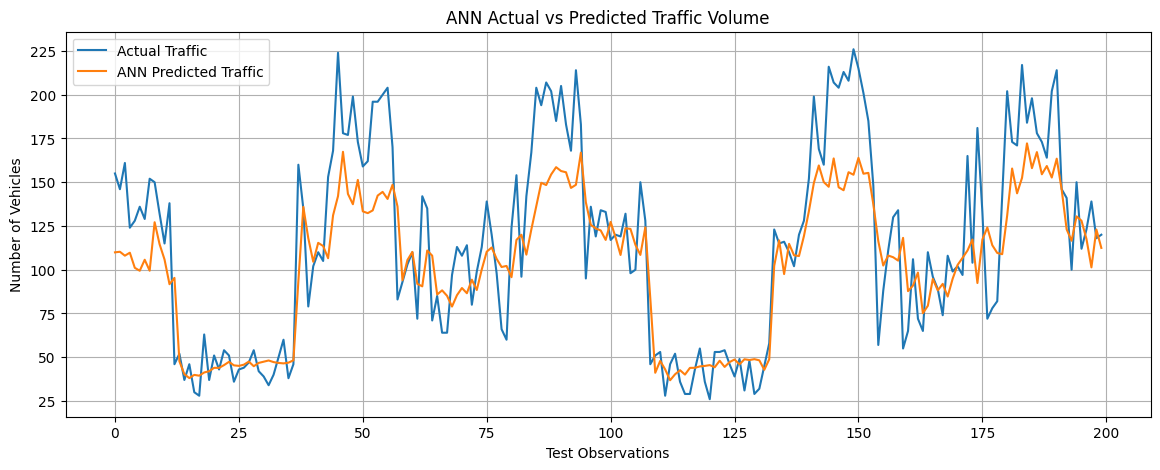

In [28]:
plt.figure(figsize=(14,5))

plt.plot(
    actual_values[:200],
    label='Actual Traffic'
)

plt.plot(
    ann_predictions[:200],
    label='ANN Predicted Traffic'
)

plt.title("ANN Actual vs Predicted Traffic Volume")

plt.xlabel("Test Observations")

plt.ylabel("Number of Vehicles")

plt.legend()

plt.grid(True)

plt.show()

In [29]:
ann_model.save(
    '/content/ann_traffic_model.keras'
)

print("ANN model saved successfully!")

ANN model saved successfully!


In [30]:
LOOKBACK = 4

# Combine training and testing features
X_all_scaled = np.vstack([
    X_train_scaled,
    X_test_scaled
])

y_all_scaled = np.vstack([
    y_train_scaled,
    y_test_scaled
])

# Prepare training sequences
X_train_lstm = []
y_train_lstm = []

for i in range(LOOKBACK, len(X_train_scaled)):

    X_train_lstm.append(
        X_train_scaled[i-LOOKBACK:i]
    )

    y_train_lstm.append(
        y_train_scaled[i]
    )

X_train_lstm = np.array(X_train_lstm)
y_train_lstm = np.array(y_train_lstm)

# Prepare testing sequences
X_test_lstm = []
y_test_lstm = []

for i in range(split_index, len(X_all_scaled)):

    X_test_lstm.append(
        X_all_scaled[i-LOOKBACK:i]
    )

    y_test_lstm.append(
        y_all_scaled[i]
    )

X_test_lstm = np.array(X_test_lstm)
y_test_lstm = np.array(y_test_lstm)

print("LSTM Training Shape:", X_train_lstm.shape)
print("LSTM Testing Shape:", X_test_lstm.shape)

LSTM Training Shape: (4680, 4, 21)
LSTM Testing Shape: (1172, 4, 21)


In [31]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

print("LSTM libraries imported successfully!")

LSTM libraries imported successfully!


In [32]:
lstm_model = Sequential([

    LSTM(
        64,
        return_sequences=True,
        input_shape=(LOOKBACK, X_train_lstm.shape[2])
    ),

    Dropout(0.2),

    LSTM(32),

    Dropout(0.2),

    Dense(16, activation='relu'),

    Dense(1)

])

lstm_model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 4, 64)          │        22,016 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 4, 64)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 34,977 (136.63 KB)

 Trainable params: 34,977 (136.63 KB)

 Non-trainable params: 0 (0.00 B)

In [33]:
lstm_model.compile(

    optimizer='adam',

    loss='mse',

    metrics=['mae']

)

print("LSTM model compiled successfully!")

LSTM model compiled successfully!


In [34]:
lstm_early_stop = EarlyStopping(

    monitor='val_loss',

    patience=5,

    restore_best_weights=True

)

lstm_history = lstm_model.fit(

    X_train_lstm,

    y_train_lstm,

    epochs=10,

    batch_size=64,

    validation_split=0.2,

    callbacks=[lstm_early_stop],

    shuffle=False,

    verbose=1

)

Epoch 1/10
59/59 ━━━━━━━━━━━━━━━━━━━━ 4s 16ms/step - loss: 0.0442 - mae: 0.1627 - val_loss: 0.0300 - val_mae: 0.1368
Epoch 2/10
59/59 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - loss: 0.0218 - mae: 0.1143 - val_loss: 0.0261 - val_mae: 0.1278
Epoch 3/10
59/59 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - loss: 0.0200 - mae: 0.1088 - val_loss: 0.0233 - val_mae: 0.1190
Epoch 4/10
59/59 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - loss: 0.0180 - mae: 0.1028 - val_loss: 0.0206 - val_mae: 0.1106
Epoch 5/10
59/59 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - loss: 0.0171 - mae: 0.0998 - val_loss: 0.0207 - val_mae: 0.1101
Epoch 6/10
59/59 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 0.0162 - mae: 0.0963 - val_loss: 0.0191 - val_mae: 0.1055
Epoch 7/10
59/59 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 0.0153 - mae: 0.0939 - val_loss: 0.0184 - val_mae: 0.1035
Epoch 8/10
59/59 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.0156 - mae: 0.0946 - val_loss: 0.0194 - val_mae: 0.1060
Epoch 9/10
59/59 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 0.0154 - 

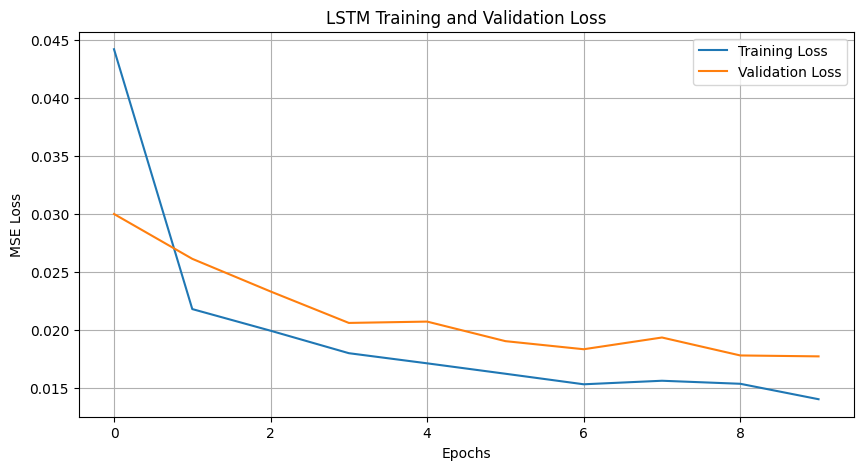

In [35]:
plt.figure(figsize=(10,5))

plt.plot(
    lstm_history.history['loss'],
    label='Training Loss'
)

plt.plot(
    lstm_history.history['val_loss'],
    label='Validation Loss'
)

plt.title("LSTM Training and Validation Loss")

plt.xlabel("Epochs")

plt.ylabel("MSE Loss")

plt.legend()

plt.grid(True)

plt.show()

In [36]:
lstm_predictions_scaled = lstm_model.predict(
    X_test_lstm
)

lstm_predictions = scaler_y.inverse_transform(
    lstm_predictions_scaled
).flatten()

actual_lstm = scaler_y.inverse_transform(
    y_test_lstm
).flatten()

print("LSTM Predictions Generated!")

for i in range(10):

    print(
        "Actual:", actual_lstm[i],
        "| Predicted:", round(lstm_predictions[i], 2)
    )

37/37 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step
LSTM Predictions Generated!
Actual: 155.0 | Predicted: 163.86
Actual: 146.0 | Predicted: 144.07
Actual: 161.0 | Predicted: 120.98
Actual: 124.0 | Predicted: 110.42
Actual: 128.0 | Predicted: 108.8
Actual: 136.0 | Predicted: 109.03
Actual: 129.0 | Predicted: 102.74
Actual: 152.0 | Predicted: 96.41
Actual: 150.0 | Predicted: 93.13
Actual: 132.0 | Predicted: 105.34


In [37]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

lstm_mae = mean_absolute_error(
    actual_lstm,
    lstm_predictions
)

lstm_mse = mean_squared_error(
    actual_lstm,
    lstm_predictions
)

lstm_rmse = np.sqrt(lstm_mse)

lstm_r2 = r2_score(
    actual_lstm,
    lstm_predictions
)

print("LSTM MODEL PERFORMANCE")

print("----------------------")

print("MAE:", round(lstm_mae, 4))

print("MSE:", round(lstm_mse, 4))

print("RMSE:", round(lstm_rmse, 4))

print("R2 Score:", round(lstm_r2, 4))

LSTM MODEL PERFORMANCE
----------------------
MAE: 24.9312
MSE: 1081.0629
RMSE: 32.8795
R2 Score: 0.6963


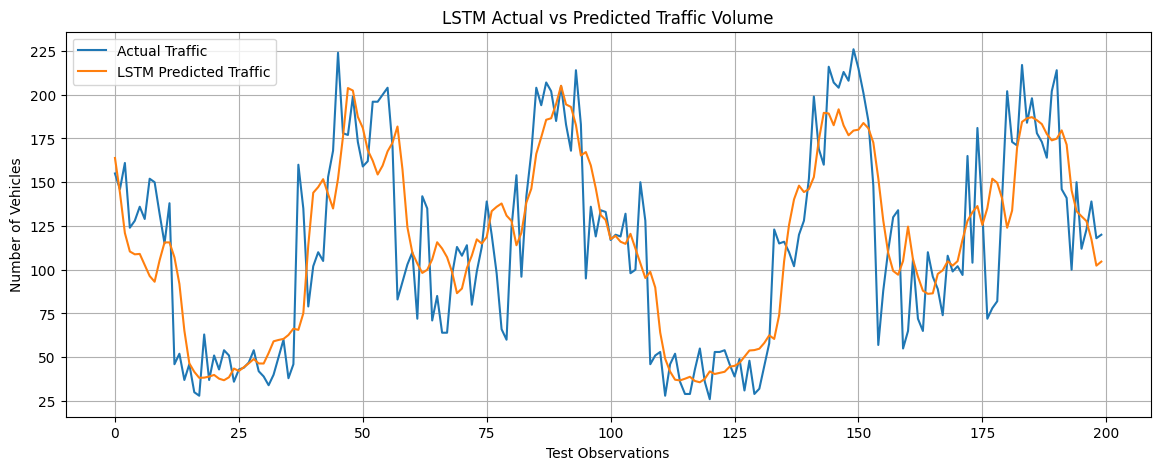

In [38]:
plt.figure(figsize=(14,5))

plt.plot(
    actual_lstm[:200],
    label='Actual Traffic'
)

plt.plot(
    lstm_predictions[:200],
    label='LSTM Predicted Traffic'
)

plt.title("LSTM Actual vs Predicted Traffic Volume")

plt.xlabel("Test Observations")

plt.ylabel("Number of Vehicles")

plt.legend()

plt.grid(True)

plt.show()

In [39]:
lstm_model.save(
    '/content/lstm_traffic_model.keras'
)

print("LSTM model saved successfully!")

LSTM model saved successfully!


Compare ANN vs LSTM

In [40]:
import pandas as pd
import numpy as np

# Calculate ANN metrics
ann_mae = mean_absolute_error(
    actual_values,
    ann_predictions
)

ann_mse = mean_squared_error(
    actual_values,
    ann_predictions
)

ann_rmse = np.sqrt(ann_mse)

ann_r2 = r2_score(
    actual_values,
    ann_predictions
)

# Calculate LSTM metrics
lstm_mae = mean_absolute_error(
    actual_lstm,
    lstm_predictions
)

lstm_mse = mean_squared_error(
    actual_lstm,
    lstm_predictions
)

lstm_rmse = np.sqrt(lstm_mse)

lstm_r2 = r2_score(
    actual_lstm,
    lstm_predictions
)

# Comparison table
comparison = pd.DataFrame({

    'Model': ['ANN', 'LSTM'],

    'MAE': [ann_mae, lstm_mae],

    'MSE': [ann_mse, lstm_mse],

    'RMSE': [ann_rmse, lstm_rmse],

    'R2 Score': [ann_r2, lstm_r2]

})

print("ANN vs LSTM Performance Comparison")

display(comparison.round(4))

ANN vs LSTM Performance Comparison


,Model,MAE,MSE,RMSE,R2 Score
0,ANN,22.7965,913.6783,30.2271,0.7433
1,LSTM,24.9312,1081.0629,32.8795,0.6963


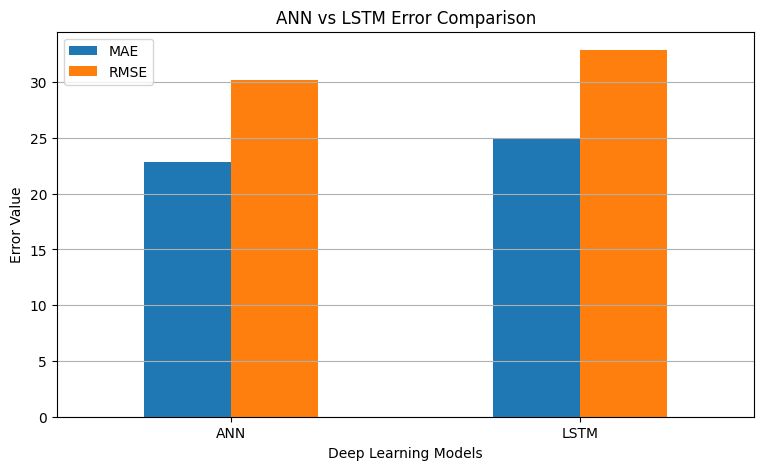

In [41]:
comparison.set_index('Model')[
    ['MAE', 'RMSE']
].plot(
    kind='bar',
    figsize=(9,5)
)

plt.title("ANN vs LSTM Error Comparison")

plt.ylabel("Error Value")

plt.xlabel("Deep Learning Models")

plt.xticks(rotation=0)

plt.legend()

plt.grid(axis='y')

plt.show()

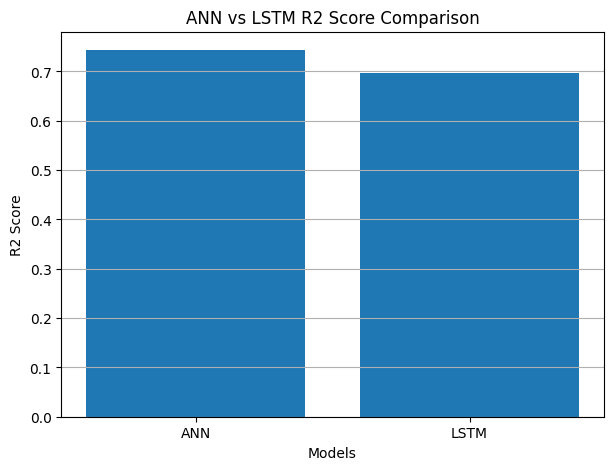

In [42]:
plt.figure(figsize=(7,5))

plt.bar(
    comparison['Model'],
    comparison['R2 Score']
)

plt.title("ANN vs LSTM R2 Score Comparison")

plt.xlabel("Models")

plt.ylabel("R2 Score")

plt.grid(axis='y')

plt.show()

In [43]:
best_model = comparison.loc[
    comparison['RMSE'].idxmin(),
    'Model'
]

print("Best performing model:", best_model)

print("\nComparison conclusion:")

if best_model == 'ANN':
    print("ANN has lower RMSE on the test dataset.")
else:
    print("LSTM has lower RMSE on the test dataset.")

Best performing model: ANN

Comparison conclusion:
ANN has lower RMSE on the test dataset.


In [44]:
from sklearn.preprocessing import LabelEncoder

# Encode congestion categories
label_encoder = LabelEncoder()

y_congestion = label_encoder.fit_transform(
    df['Traffic Situation']
)

print("Congestion categories:")

for i, category in enumerate(label_encoder.classes_):
    print(i, ":", category)

# Use historical features and time features
X_congestion = df[feature_columns].values.astype('float32')

# Chronological split
split_index_cls = int(len(df) * 0.80)

Xc_train = X_congestion[:split_index_cls]
Xc_test = X_congestion[split_index_cls:]

yc_train = y_congestion[:split_index_cls]
yc_test = y_congestion[split_index_cls:]

print("Training shape:", Xc_train.shape)
print("Testing shape:", Xc_test.shape)

Congestion categories:
0 : heavy
1 : high
2 : low
3 : normal
Training shape: (4684, 21)
Testing shape: (1172, 21)


In [45]:
from sklearn.preprocessing import MinMaxScaler

congestion_scaler = MinMaxScaler()

Xc_train_scaled = congestion_scaler.fit_transform(
    Xc_train
)

Xc_test_scaled = congestion_scaler.transform(
    Xc_test
)

print("Congestion data normalized successfully!")

Congestion data normalized successfully!


In [46]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout

congestion_model = Sequential([

    Dense(
        128,
        activation='relu',
        input_shape=(Xc_train_scaled.shape[1],)
    ),

    Dropout(0.2),

    Dense(64, activation='relu'),

    Dropout(0.2),

    Dense(32, activation='relu'),

    Dense(
        len(label_encoder.classes_),
        activation='softmax'
    )

])

congestion_model.compile(

    optimizer='adam',

    loss='sparse_categorical_crossentropy',

    metrics=['accuracy']

)

congestion_model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_6 (Dense)                 │ (None, 128)            │         2,816 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 4)              │           132 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 13,284 (51.89 KB)

 Trainable params: 13,284 (51.89 KB)

 Non-trainable params: 0 (0.00 B)

In [50]:
ann_model.save(
    '/content/ann_traffic_model.keras'
)

lstm_model.save(
    '/content/lstm_traffic_model.keras'
)

congestion_model.save(
    '/content/congestion_model.keras'
)

print("All models saved successfully!")

All models saved successfully!


In [52]:
from sklearn.utils.class_weight import compute_class_weight
import numpy as np

classes = np.unique(yc_train)

weights = compute_class_weight(
    class_weight='balanced',
    classes=classes,
    y=yc_train
)

class_weights = dict(zip(classes, weights))

print("Class Weights:")

for key, value in class_weights.items():
    print(
        label_encoder.inverse_transform([key])[0],
        ":", round(value, 3)
    )

Class Weights:
heavy : 1.373
high : 4.08
low : 1.838
normal : 0.403


In [53]:
congestion_history = congestion_model.fit(

    Xc_train_scaled,

    yc_train,

    epochs=50,

    batch_size=64,

    validation_split=0.2,

    callbacks=[early_stop],

    class_weight=class_weights,

    verbose=1

)

Epoch 1/50
59/59 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - accuracy: 0.6023 - loss: 1.1474 - val_accuracy: 0.4707 - val_loss: 1.1033
Epoch 2/50
59/59 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.5570 - loss: 1.0212 - val_accuracy: 0.4824 - val_loss: 1.0768
Epoch 3/50
59/59 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.5276 - loss: 0.9730 - val_accuracy: 0.5347 - val_loss: 1.0037
Epoch 4/50
59/59 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.5324 - loss: 0.9377 - val_accuracy: 0.5069 - val_loss: 1.0304
Epoch 5/50
59/59 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.5442 - loss: 0.9210 - val_accuracy: 0.5112 - val_loss: 1.0166


In [54]:
congestion_predictions_prob = congestion_model.predict(
    Xc_test_scaled
)

congestion_predictions = np.argmax(
    congestion_predictions_prob,
    axis=1
)

print(classification_report(
    yc_test,
    congestion_predictions,
    labels=np.arange(len(label_encoder.classes_)),
    target_names=label_encoder.classes_,
    zero_division=0
))

37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step
              precision    recall  f1-score   support

       heavy       0.64      0.94      0.76       272
        high       0.13      0.55      0.21        78
         low       0.43      0.05      0.09       189
      normal       0.75      0.50      0.60       633

    accuracy                           0.53      1172
   macro avg       0.49      0.51      0.42      1172
weighted avg       0.63      0.53      0.53      1172



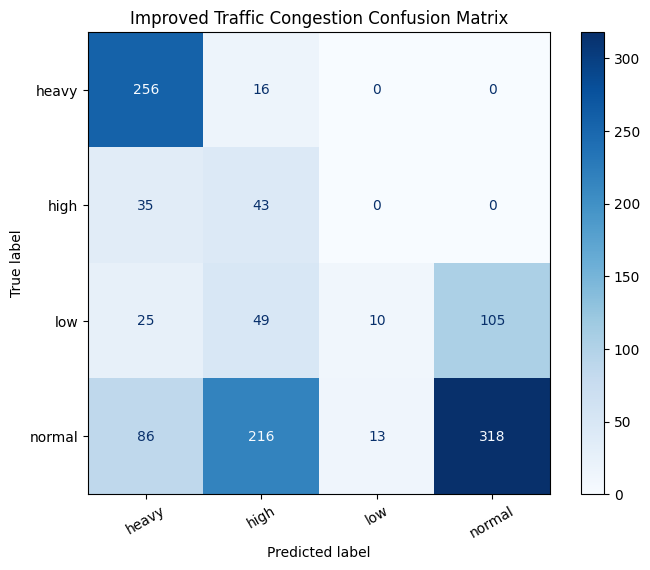

In [55]:
cm = confusion_matrix(
    yc_test,
    congestion_predictions,
    labels=np.arange(len(label_encoder.classes_))
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=label_encoder.classes_
)

fig, ax = plt.subplots(figsize=(8,6))

disp.plot(
    cmap='Blues',
    xticks_rotation=30,
    ax=ax
)

plt.title("Improved Traffic Congestion Confusion Matrix")

plt.show()

In [56]:
congestion_model.save(
    '/content/congestion_model.keras'
)

print("Improved congestion model saved!")

Improved congestion model saved!


In [57]:
from sklearn.metrics import classification_report

print(
    classification_report(
        yc_test,
        congestion_predictions,
        target_names=label_encoder.classes_,
        zero_division=0
    )
)

              precision    recall  f1-score   support

       heavy       0.64      0.94      0.76       272
        high       0.13      0.55      0.21        78
         low       0.43      0.05      0.09       189
      normal       0.75      0.50      0.60       633

    accuracy                           0.53      1172
   macro avg       0.49      0.51      0.42      1172
weighted avg       0.63      0.53      0.53      1172

